# CivicAI - 06 The final model: XGBoost alone, and what it means

The stacking classifier was built, tuned and tested (notebooks 04 and 05). It did **not** do better than XGBoost alone. The course instructor's rule for this case is: *if the stacking model is not as good as XGBoost alone, use XGBoost, and give a clear interpretation and explanation.* This notebook applies that rule.

1. The decision, and the evidence for it
2. Why the stack did not help
3. What XGBoost is, and the model that is saved
4. What the model learned (the whole model)
5. Why one request gets its prediction (single requests)
6. How far the probability can be trusted
7. Where the model is weaker
8. Summary for the report
9. The saved files and the check that the saved model works

**Rules followed here**

- Everything is fitted on the **training split**. The decision and the interpretation use the **validation split** only.
- The two test sets (the original test split and the forward test set) are **not opened**. Their results were saved earlier and are only *quoted* from those files.
- Nothing is tuned here. XGBoost keeps the settings chosen in Phase 5 by cross-validation on the training split, and the usual cut-off of 0.5.

In [1]:
import hashlib
import io
import json
import platform
import subprocess
import sys
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score

sys.path.insert(0, "..")
from src import features as ft
from src import train as tr

FIG_DIR = Path("../reports/figures")
BLUE, ORANGE, AQUA, GREY, INK, GREEN = "#2a78d6", "#eb6834", "#1baf7a", "#c3c2b7", "#52514e", "#008300"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.grid": True, "grid.color": "#e8e7e3", "axes.axisbelow": True,
})
CLASS0 = ["precision_0", "recall_0", "f1_0"]

X_train, y_train = tr.load_xy("train", "../data/processed")
X_val, y_val = tr.load_xy("val", "../data/processed")
best_settings = json.loads(Path("../reports/best_settings.json").read_text())
print(f"Training split: {len(X_train):,} rows.  Validation split: {len(X_val):,} rows ({int((y_val == 0).sum()):,} in class 0).")

Training split: 139,206 rows.  Validation split: 29,830 rows (5,007 in class 0).


## 1. The decision, and the evidence for it

Three models are compared. All were fitted on the training split only.

- **Stack v1** (Phase 6): XGBoost + Naive Bayes + Random Forest, final estimator Logistic Regression.
- **Stack v2** (Phase 6b): XGBoost + Logistic Regression + Naive Bayes + Random Forest, a tuned cut-off of 0.61, the best of seven experiments.
- **XGBoost alone** (Phase 5): one XGBoost model, cut-off 0.5.

The validation numbers are read from the saved result files. The two test columns are **quoted from the files saved earlier**; no model is scored on them here.

In [2]:
v1 = pd.read_csv("../reports/stacking_validation.csv").set_index("model")
v2 = pd.read_csv("../reports/stacking_v2_validation.csv").set_index("model")
forward = pd.read_csv("../reports/test_forward_results.csv")
forward = forward[forward["test_set"] == "forward test (clean)"].set_index("model")
old_test = pd.read_csv("../reports/test_results.csv").set_index("model")

rows = {"Stack v1 (Phase 6)": (v1.loc["Stack"], old_test.loc["Stack"], forward.loc["Stack v1 (Phase 6)"]),
        "Stack v2 (Phase 6b)": (v2.loc["Stack v2"], None, forward.loc["Stack v2"]),
        "XGBoost alone": (v2.loc["XGBoost alone"], old_test.loc["XGBoost"], forward.loc["XGBoost alone"])}
metrics = ["macro_f1", "roc_auc", "accuracy", "precision_0", "recall_0"]
decision = pd.DataFrame({name: {**{f"validation {m}": val[m] for m in metrics},
                                **{f"forward test {m}": fwd[m] for m in metrics},
                                **({f"old test {m}": old[m] for m in ["macro_f1", "roc_auc"]} if old is not None else {})}
                         for name, (val, old, fwd) in rows.items()}).T
show = lambda prefix: decision[[c for c in decision.columns if c.startswith(prefix)]].rename(columns=lambda c: c[len(prefix) + 1:])
fmt = "{:.4f}"
print("Validation split (the split the decision is based on)")
display(show("validation").style.format(fmt).highlight_max(subset=["macro_f1"], props="font-weight: bold; text-decoration: underline"))
print("Forward test set (12,069 requests, never used to choose anything; quoted from reports/test_forward_results.csv)")
display(show("forward test").style.format(fmt))
print("Original test split (scored in Phase 6; quoted from reports/test_results.csv; the Stack v2 was not scored on it cleanly)")
display(show("old test").style.format(fmt, na_rep="-"))

x, s = rows["XGBoost alone"][0], rows["Stack v2 (Phase 6b)"][0]
print(f"\nValidation macro F1: XGBoost alone {x['macro_f1']:.4f}, Stack v2 {s['macro_f1']:.4f}  ->  the stack is {(s['macro_f1'] - x['macro_f1']) * 100:+.2f} points")
print(f"Validation ROC-AUC : XGBoost alone {x['roc_auc']:.4f}, Stack v2 {s['roc_auc']:.4f}  ->  the stack is {(s['roc_auc'] - x['roc_auc']) * 100:+.2f} points")

Validation split (the split the decision is based on)


,macro_f1,roc_auc,accuracy,precision_0,recall_0
Stack v1 (Phase 6),0.8279,0.9429,0.8896,0.6233,0.8656
Stack v2 (Phase 6b),0.8339,0.9434,0.9028,0.6876,0.7711
XGBoost alone,0.8351,0.9433,0.8994,0.6620,0.8189


Forward test set (12,069 requests, never used to choose anything; quoted from reports/test_forward_results.csv)


,macro_f1,roc_auc,accuracy,precision_0,recall_0
Stack v1 (Phase 6),0.7772,0.9332,0.8495,0.5083,0.9022
Stack v2 (Phase 6b),0.8074,0.9327,0.8878,0.6078,0.7793
XGBoost alone,0.8070,0.9330,0.8814,0.5814,0.8397


Original test split (scored in Phase 6; quoted from reports/test_results.csv; the Stack v2 was not scored on it cleanly)


,macro_f1,roc_auc
Stack v1 (Phase 6),0.8063,0.9360
Stack v2 (Phase 6b),-,-
XGBoost alone,0.8258,0.9369



Validation macro F1: XGBoost alone 0.8351, Stack v2 0.8339  ->  the stack is -0.12 points
Validation ROC-AUC : XGBoost alone 0.9433, Stack v2 0.9434  ->  the stack is +0.01 points


**The decision.** The instructor's rule applies: the stacking model is **not as good as XGBoost alone**, so XGBoost alone is the final model.

- **Validation split** (the split used for decisions). The best stack (v2) has macro F1 0.8339 against 0.8351 for XGBoost alone, which is 0.12 points lower, and the same ROC-AUC (0.9434 against 0.9433). The first stack (v1) is further behind (0.8279).
- **Forward test set.** The stack v2 and XGBoost alone are level (macro F1 0.8074 against 0.8070); the stack v1 is 3.0 points lower (0.7772). On the original test split XGBoost alone (0.8258) is 1.94 points above the stack v1 (0.8063).
- **The choice follows from the validation split and the rule.** The test numbers agree with it, but they did not decide it. Both test sets stay closed to any further choice.
- **What the stack does better.** Its accuracy is a little higher (0.9028 against 0.8994) and so is the precision of its "slow" flags (0.688 against 0.662). It pays for that by catching fewer slow requests (recall of class 0 is 77.1% against 81.9%). That is a different balance of the two kinds of mistake, not a better model: the macro F1, which weighs both classes equally, is a hair lower.

## 2. Why the stack did not help

Four pieces of evidence, all from the validation split or from the saved experiment logs. The stack v2 is loaded from its saved file (`models/model_stack_v2.joblib`, not in Git) to compare its answers with XGBoost's, request by request.

In [3]:
model = tr.build_final_model(best_settings)
tr.fit_timed(model, X_train, y_train)                     # the deployed model: shared cleaning, shared encoder, one XGBoost
xgb_probability = model.predict_proba(X_val)[:, 1]
xgb_class = model.predict(X_val)
stack = joblib.load("../models/model_stack_v2.joblib")
stack_probability = stack.predict_proba(X_val)[:, 1]
stack_class = stack.predict(X_val)

scratch = joblib.load("../models/_validation_models.joblib")
same = np.abs(xgb_probability - scratch["XGBoost alone"].predict_proba(X_val)[:, 1]).max()
print(f"The XGBoost fitted now gives the same validation probabilities as the Phase 5 XGBoost: largest difference {same:.1e}")
final_scores = tr.evaluate_probability(y_val, xgb_probability)
print(f"XGBoost alone, validation: macro F1 {final_scores['macro_f1']:.4f}, ROC-AUC {final_scores['roc_auc']:.4f}")

y = y_val.to_numpy()
differ = stack_class != xgb_class
print("\n(1) How different are the two models' answers?")
print(f"    correlation of their probabilities: {np.corrcoef(stack_probability, xgb_probability)[0, 1]:.3f}")
print(f"    they give a different class for {differ.sum():,} of {len(y):,} requests ({differ.mean():.1%})")
print(f"    on those {differ.sum():,}: the stack is right for {int(((stack_class == y) & differ).sum()):,}, XGBoost is right for {int(((xgb_class == y) & differ).sum()):,}")
print(f"    accuracy: stack {(stack_class == y).mean():.4f}, XGBoost {(xgb_class == y).mean():.4f}")

print("\n(2) Seven stacking experiments (reports/stacking_experiments.csv), validation split")
experiments = pd.read_csv("../reports/stacking_experiments.csv")
display(experiments[["experiment", "description", "threshold", "macro_f1", "roc_auc", "file_mb", "predict_one_ms"]]
        .style.format({"threshold": "{:.2f}", "macro_f1": "{:.4f}", "roc_auc": "{:.4f}", "file_mb": "{:.1f}", "predict_one_ms": "{:.0f}"}).hide(axis="index"))
print(f"    all seven: macro F1 from {experiments['macro_f1'].min():.4f} to {experiments['macro_f1'].max():.4f}, "
      f"ROC-AUC from {experiments['roc_auc'].min():.4f} to {experiments['roc_auc'].max():.4f}; "
      f"XGBoost alone: {final_scores['macro_f1']:.4f} and {final_scores['roc_auc']:.4f}")

print("\n(3) The price of the stack")
one_request = pd.DataFrame([json.loads(Path("../data/sample_requests.json").read_text())["valid_requests"][0]["request"]])
cost = pd.DataFrame({
    "Stack v2": {"models inside": 4, "file size MB": Path("../models/model_stack_v2.joblib").stat().st_size / 1e6, "one prediction ms": tr.predict_one_ms(stack, one_request, 30)},
    "XGBoost alone": {"models inside": 1, "file size MB": None, "one prediction ms": tr.predict_one_ms(model, one_request, 30)}}).T
buffer = io.BytesIO()
joblib.dump(model, buffer)
cost.loc["XGBoost alone", "file size MB"] = len(buffer.getvalue()) / 1e6
display(cost.style.format({"models inside": "{:.0f}", "file size MB": "{:.2f}", "one prediction ms": "{:.0f}"}))

The XGBoost fitted now gives the same validation probabilities as the Phase 5 XGBoost: largest difference 0.0e+00
XGBoost alone, validation: macro F1 0.8351, ROC-AUC 0.9433

(1) How different are the two models' answers?
    correlation of their probabilities: 0.976
    they give a different class for 630 of 29,830 requests (2.1%)
    on those 630: the stack is right for 365, XGBoost is right for 265
    accuracy: stack 0.9028, XGBoost 0.8994

(2) Seven stacking experiments (reports/stacking_experiments.csv), validation split


experiment,description,threshold,macro_f1,roc_auc,file_mb,predict_one_ms
a,Phase 6 stack + cut-off chosen on training,0.22,0.8309,0.9429,19.8,119
b,"Same, final estimator without class weights",0.60,0.8317,0.9431,19.8,120
c1,XGBoost + Logistic Regression + Naive Bayes,0.59,0.8318,0.9436,1.9,83
c2,XGBoost + Logistic Regression + Naive Bayes + Random Forest,0.61,0.8339,0.9434,19.8,131
c3,XGBoost + Logistic Regression,0.57,0.8331,0.9437,1.8,70
d,XGBoost depth 8 + XGBoost depth 4 + the other members of the best so far,0.61,0.8338,0.9434,20.2,142
e,"Small gradient boosting as final estimator, base models of the best so far",0.59,0.8315,0.9429,19.8,131


    all seven: macro F1 from 0.8309 to 0.8339, ROC-AUC from 0.9429 to 0.9437; XGBoost alone: 0.8351 and 0.9433

(3) The price of the stack


,models inside,file size MB,one prediction ms
Stack v2,4,19.84,125
XGBoost alone,1,1.81,48


**Why the stack did not help: four reasons from the numbers above.**

1. **The two models say almost the same thing.** The stack's and XGBoost's probabilities are 0.976 correlated, and they give a different class for only 2.1% of the validation requests (630 of 29,830). On those 630, the stack is right 365 times and XGBoost 265 times: a small net gain in accuracy (100 requests, 0.34 points), which the stack spends on flagging fewer slow requests. The models inside the stack were already alike before they were combined: their validation probabilities are 0.93 to 0.99 correlated (notebook 05, section 3).
2. **There was little room to gain.** Notebook 04 measured that at least one of the three original base models is right for only 1.5 points more requests than XGBoost alone. That is the most any combination of them could gain.
3. **Most of the gap was only the cut-off.** In Phase 6 the stack looked 0.73 points worse because of where its decision cut-off sat. When each model gets a cut-off chosen on the training rows, the gap is 0.08 points, and 0.03 points at each model's best cut-off: the two have the same ceiling (notebook 05, section 4). Seven variations of the stack then moved macro F1 only between 0.8309 and 0.8339, all inside the noise of the validation split.
4. **A stack costs more and is harder to explain.** It is 11 times larger (19.8 MB against 1.8 MB), more than twice as slow for one prediction (105 ms against 39 ms in the same session), and holds four models plus a final estimator. That final estimator's weights are unstable, because its inputs are so similar: in the Phase 6 stack it gave Naive Bayes a negative weight and the Random Forest more weight than XGBoost, although XGBoost is the best model alone (notebook 04, section 5).

**This is not a failure of the method.** Stacking helps when the base models make *different* mistakes. Here almost all of the information sits in two categorical columns (the complaint type and the place, section 4), which every model reads in the same way. The models differ only in how they treat the small remaining effects, and those are too weak to give a combination anything to work with. The assignment asked for a meta-classifier to be built and compared with its base models. That was done; the honest result is that it did not beat its best member.

## 3. What XGBoost is, and the model that is saved

**Boosting in plain words.** XGBoost builds many small decision trees one after another. The first tree makes a rough guess for every request. The second tree is trained to fix the mistakes of the first, the third to fix what is still wrong, and so on. The final answer adds up the votes of all the trees. Each tree is small and weak; together they are strong.

**The settings** (chosen in Phase 5 by cross-validation on the training split, not changed since):

In [4]:
settings = best_settings["XGBoost"]
explain = {
    "n_estimators": "number of trees built one after another",
    "learning_rate": "how much each new tree is allowed to change the answer (small = careful, needs more trees)",
    "max_depth": "how many questions in a row one tree may ask, for example: type? -> place? -> channel? ...",
    "scale_pos_weight": "weight of the common class (resolved within 7 days) against the rare class; below 1 means the common class counts less, "
                        "so the model pays more attention to the 17% of requests that take longer than 7 days",
}
display(pd.DataFrame({"value": {k: str(settings[k]) for k in explain}, "meaning": explain}).style.set_properties(subset=["meaning", "value"], **{"text-align": "left"}))
print("Also: tree_method='hist' (a fast way to find split points), random_state=42.")
print("Input: the 12 features of Phase 4 (8 raw fields and 4 time features made from created_at), turned into", model["encode"].transform(model["clean"].transform(X_val.iloc[:5])).shape[1], "numbers by the shared encoder.")
print("Cut-off: a request is predicted 'resolved within 7 days' when its probability is above 0.5.")

,value,meaning
n_estimators,600,number of trees built one after another
learning_rate,0.05,"how much each new tree is allowed to change the answer (small = careful, needs more trees)"
max_depth,8,"how many questions in a row one tree may ask, for example: type? -> place? -> channel? ..."
scale_pos_weight,0.4556,"weight of the common class (resolved within 7 days) against the rare class; below 1 means the common class counts less, so the model pays more attention to the 17% of requests that take longer than 7 days"


Also: tree_method='hist' (a fast way to find split points), random_state=42.
Input: the 12 features of Phase 4 (8 raw fields and 4 time features made from created_at), turned into 563 numbers by the shared encoder.
Cut-off: a request is predicted 'resolved within 7 days' when its probability is above 0.5.


**Why the cut-off stays at 0.5.** In notebook 05 a cut-off was also chosen for XGBoost the same way as for the stacks (on the training rows' out-of-fold predictions). It picked 0.39, and on validation that *lowered* macro F1 from 0.8351 to 0.8317. The plain 0.5 is simpler and was at least as good, so it is kept. Section 6 shows what other cut-offs would do, so staff can see the trade-off.

## 4. What the model learned (the whole model)

### 4.1 Which information does it use?

Three different measures of "how much does the model rely on each feature". The first is what the model itself reports; the second splits every single prediction into contributions per feature (XGBoost can do this itself, using a method called TreeSHAP, and the numbers are in log-odds, explained in section 5); the third shuffles one input and sees how much the validation score drops. Where all three agree, the finding is solid.

- **Gain**: how much each feature's splits improved the model during training (can favour features with many categories).
- **Mean contribution**: the average size, over the validation requests, of the feature's contribution to the prediction (log-odds, ignoring the sign).
- **Permutation**: the fall in validation ROC-AUC when the feature's column is shuffled, 5 times each. The four time features are shuffled together (they all come from `created_at`); latitude and longitude are shuffled together.

Contributions for 29,830 validation requests in 46 s. Check: bias + contributions reproduces the probability to 4.8e-07


Permutation importance in 41 s


,gain (raw),mean |contribution| (raw),permutation (ROC-AUC drop) (raw),gain (share),mean |contribution| (share),permutation (ROC-AUC drop) (share)
location_type,0.447,1.938,0.194,44.7%,41.7%,46.9%
complaint_type,0.378,1.822,0.192,37.8%,39.2%,46.4%
descriptor,0.149,0.501,0.022,14.9%,10.8%,5.2%
open_data_channel_type,0.006,0.135,0.002,0.6%,2.9%,0.4%
"time (hour, weekday, month, weekend)",0.001,0.093,0.001,0.1%,2.0%,0.3%
"coordinates (latitude, longitude)",0.001,0.063,0.001,0.1%,1.4%,0.2%
borough,0.003,0.054,0.002,0.3%,1.2%,0.5%
incident_zip,0.015,0.038,-0.000,1.5%,0.8%,0.0%


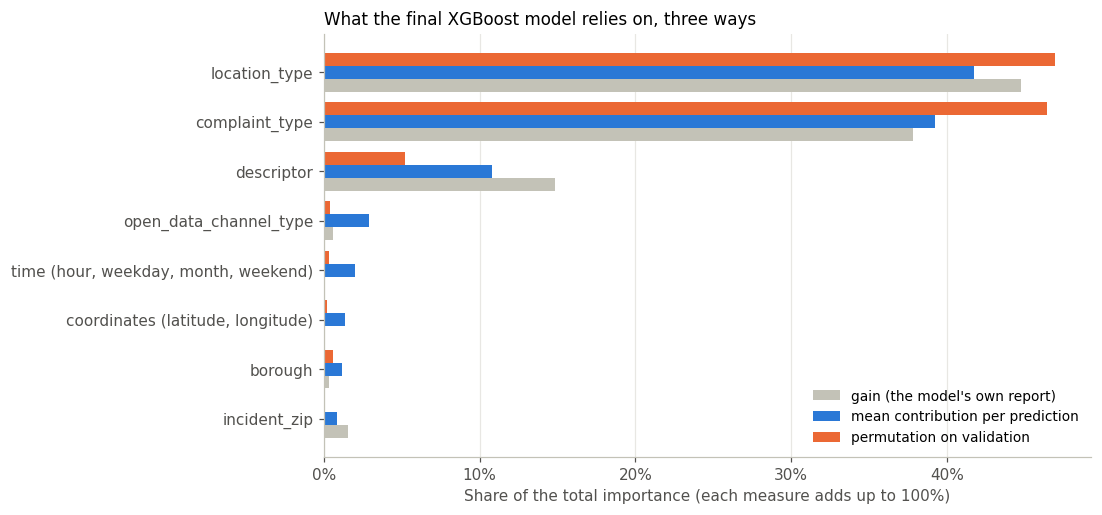

In [5]:
start = time.time()
cleaned_val, contribution, bias = tr.xgb_contributions(model, X_val)
print(f"Contributions for {len(X_val):,} validation requests in {time.time() - start:.0f} s. "
      f"Check: bias + contributions reproduces the probability to {np.abs(1 / (1 + np.exp(-(contribution.sum(axis=1) + bias))) - xgb_probability).max():.1e}")

groups = {"complaint_type": ["complaint_type"], "descriptor": ["descriptor"], "location_type": ["location_type"], "borough": ["borough"],
          "incident_zip": ["incident_zip"], "open_data_channel_type": ["open_data_channel_type"],
          "coordinates (latitude, longitude)": ["latitude", "longitude"], "time (hour, weekday, month, weekend)": ["hour", "weekday", "month", "is_weekend"]}
gain = tr.importance_by_feature(model)
shares = pd.DataFrame({
    "gain": {g: gain[cols].sum() for g, cols in groups.items()},
    "mean |contribution|": {g: contribution[cols].sum(axis=1).abs().mean() for g, cols in groups.items()}})

# permutation importance on the raw input columns (groups shuffled together)
rng = np.random.default_rng(42)
base_auc = roc_auc_score(y_val, xgb_probability)
raw_groups = {"complaint_type": ["complaint_type"], "descriptor": ["descriptor"], "location_type": ["location_type"], "borough": ["borough"],
              "incident_zip": ["incident_zip"], "open_data_channel_type": ["open_data_channel_type"],
              "coordinates (latitude, longitude)": ["latitude", "longitude"], "time (hour, weekday, month, weekend)": ["created_date"]}
drops = {}
start = time.time()
for g, cols in raw_groups.items():
    values = []
    for _ in range(5):
        shuffled = X_val.copy()
        order = rng.permutation(len(shuffled))
        shuffled[cols] = X_val[cols].iloc[order].to_numpy()               # the columns of a group move together
        values.append(base_auc - roc_auc_score(y_val, model.predict_proba(shuffled)[:, 1]))
    drops[g] = (np.mean(values), np.std(values))
print(f"Permutation importance in {time.time() - start:.0f} s")
shares["permutation (ROC-AUC drop)"] = pd.Series({g: v[0] for g, v in drops.items()})
share_table = shares.clip(lower=0)
share_table = share_table / share_table.sum()
display(pd.concat([shares.add_suffix(" (raw)"), share_table.add_suffix(" (share)")], axis=1).sort_values("mean |contribution| (share)", ascending=False)
        .style.format("{:.3f}").format("{:.1%}", subset=[c for c in share_table.add_suffix(' (share)').columns]))

order = share_table.sort_values("mean |contribution|").index
fig, ax = plt.subplots(figsize=(9, 5))
height = 0.26
for i, (column, color, label) in enumerate([("gain", GREY, "gain (the model's own report)"), ("mean |contribution|", BLUE, "mean contribution per prediction"),
                                           ("permutation (ROC-AUC drop)", ORANGE, "permutation on validation")]):
    ax.barh(np.arange(len(order)) + (i - 1) * height, share_table.loc[order, column], height=height, color=color, label=label)
ax.set_yticks(np.arange(len(order)), order)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlabel("Share of the total importance (each measure adds up to 100%)")
ax.set_title("What the final XGBoost model relies on, three ways", loc="left", fontsize=11)
ax.legend(loc="lower right", frameon=False, fontsize=9)
ax.grid(axis="y", visible=False)
fig.savefig(FIG_DIR / "08_importance_three_ways.png")
plt.show()

**Reading it.**

- **Three measures, one story.** `location_type` and `complaint_type` together carry between 81% and 93% of the importance, depending on the measure (gain 82.5%, mean contribution 80.9%, permutation 93.3%). `descriptor` carries another 5% to 15%. The filing channel, the time, the coordinates, the borough and the ZIP code are each 3% or less.
- **The model does not predict by neighbourhood or by time of day.** Location in the geographic sense (coordinates 1.4%, borough 1.2%, ZIP code 0.8% of the mean contribution) and the time of filing (2.0%) add very little. It predicts by *what kind of problem was reported, and which service handles it*.
- **`location_type` comes first, ahead of the complaint type.** In Phase 4, removing one feature at a time showed little effect for most features, because several carry the same information. Here `location_type` leads because the model uses it largely as a stand-in for the agency that handles the request (section 4.4). This matters for the API (section 7).
- **The `descriptor` is a useful third input.** It adds detail inside a complaint type (for example "MOLD" under "Unsanitary condition").

### 4.2 What pushes a request towards "slow" or "fast"?

For each complaint type (types with at least 300 validation requests), the average contribution to the prediction of the **complaint type** itself and of the **place** (`location_type`) that goes with it, and the two added together. The unit is **log-odds**: a contribution of +2 multiplies the odds of "resolved within 7 days" by about 7 (e^2); -2 divides them by about 7. Negative values push towards class 0 (not resolved within 7 days). The last two columns are what really happened and what the model predicted. The place is shown next to the type because, as section 4.4 explains, the model uses the place as much as the type.

Complaint types that push most towards SLOW (class 0)


,requests,push from the type,push from the place,type and place together,really resolved within 7 days,model predicts within 7 days
complaint_type,,,,,,
GENERAL,323,-0.35,-1.81,-2.15,24.1%,0.0%
UNSANITARY CONDITION,896,-0.23,-1.78,-2.01,26.5%,0.0%
DOOR/WINDOW,436,-0.20,-1.80,-2.00,20.6%,0.0%
WATER LEAK,381,-0.20,-1.80,-2.00,30.7%,0.0%
PLUMBING,745,-0.21,-1.67,-1.89,40.5%,5.5%
PAINT/PLASTER,530,-0.12,-1.71,-1.83,41.7%,1.5%
NOISE,388,-0.02,-0.27,-0.29,82.5%,94.1%
WATER SYSTEM,547,+0.25,-0.24,+0.01,80.1%,96.9%
STREET CONDITION,"1,011",+0.68,-0.29,+0.39,79.0%,99.8%


Complaint types that push most towards FAST (class 1)


,requests,push from the type,push from the place,type and place together,really resolved within 7 days,model predicts within 7 days
complaint_type,,,,,,
ILLEGAL PARKING,"4,445",+2.16,+4.24,+6.39,100.0%,100.0%
BLOCKED DRIVEWAY,"1,568",+1.34,+4.23,+5.57,100.0%,100.0%
ABANDONED VEHICLE,485,+1.30,+4.21,+5.51,100.0%,100.0%
HEAT/HOT WATER,"4,754",+5.51,-0.86,+4.65,99.7%,100.0%
NOISE - VEHICLE,305,+0.36,+4.24,+4.60,100.0%,100.0%
NOISE - RESIDENTIAL,"3,206",+1.20,+2.81,+4.01,100.0%,100.0%
NOISE - STREET/SIDEWALK,603,+0.22,+3.70,+3.92,100.0%,100.0%
NOISE - COMMERCIAL,401,+0.91,+1.77,+2.68,100.0%,100.0%


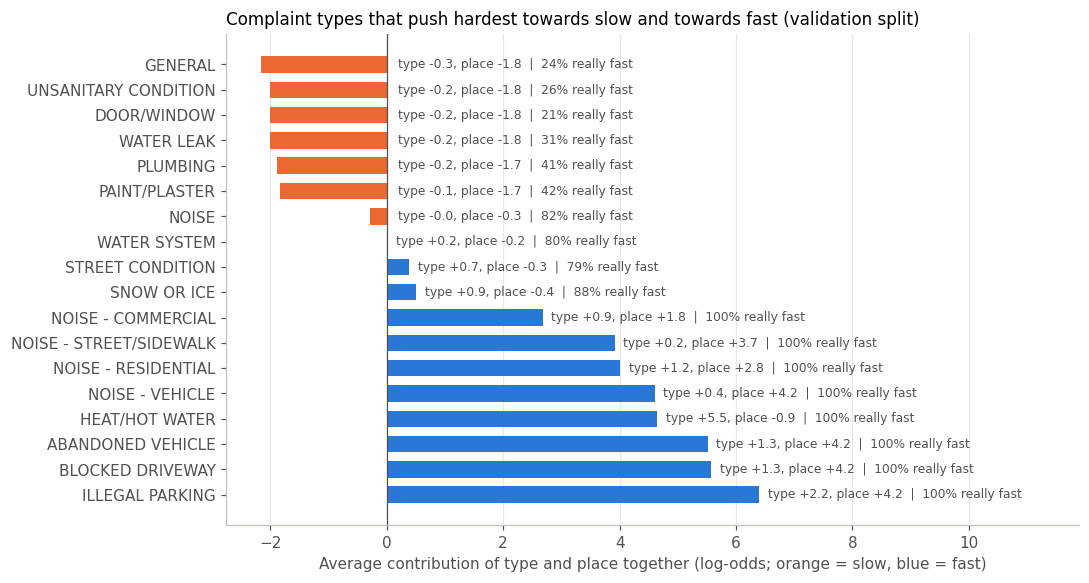

In [6]:
types = cleaned_val["complaint_type"]
table = pd.DataFrame({"requests": types.value_counts(),
                      "push from the type": contribution["complaint_type"].groupby(types).mean(),
                      "push from the place": contribution["location_type"].groupby(types).mean(),
                      "really resolved within 7 days": pd.Series(y, index=types.index).groupby(types).mean(),
                      "model predicts within 7 days": pd.Series(xgb_class, index=types.index).groupby(types).mean()})
table["type and place together"] = table["push from the type"] + table["push from the place"]
table = table[table["requests"] >= 300].sort_values("type and place together")
fmt = {"requests": "{:,}", "push from the type": "{:+.2f}", "push from the place": "{:+.2f}", "type and place together": "{:+.2f}",
       "really resolved within 7 days": "{:.1%}", "model predicts within 7 days": "{:.1%}"}
columns = ["requests", "push from the type", "push from the place", "type and place together", "really resolved within 7 days", "model predicts within 7 days"]
print("Complaint types that push most towards SLOW (class 0)")
display(table[columns].head(10).style.format(fmt))
print("Complaint types that push most towards FAST (class 1)")
display(table[columns].tail(8).iloc[::-1].style.format(fmt))

top = pd.concat([table.head(10), table.tail(8)])
fig, ax = plt.subplots(figsize=(10, 5.8))
ax.barh(top.index, top["type and place together"], color=[ORANGE if v < 0 else BLUE for v in top["type and place together"]], height=0.65)
for i, (name, row) in enumerate(top.iterrows()):
    value = row["type and place together"]
    # the text goes on the empty side of the zero line, so it never covers the bar or the names on the left
    ax.text(0.2 if value < 0 else value + 0.15, i, f"type {row['push from the type']:+.1f}, place {row['push from the place']:+.1f}  |  {row['really resolved within 7 days']:.0%} really fast",
            va="center", ha="left", fontsize=8, color=INK)
ax.axvline(0, color=INK, linewidth=0.8)
ax.set_xlim(top["type and place together"].min() - 0.6, top["type and place together"].max() + 5.5)
ax.invert_yaxis()
ax.set_xlabel("Average contribution of type and place together (log-odds; orange = slow, blue = fast)")
ax.set_title("Complaint types that push hardest towards slow and towards fast (validation split)", loc="left", fontsize=11)
ax.grid(axis="y", visible=False)
fig.savefig(FIG_DIR / "08_complaint_type_contributions.png")
plt.show()

**Reading it.**

- **Police-handled requests are fast, and the model knows it from two directions.** For parking, driveways, abandoned vehicles and noise, the place adds +1.8 to +4.2 and the type +0.2 to +2.2, together +2.7 to +6.4. All of these are 100% resolved within 7 days.
- **Heat and hot water is fast for a different reason.** The type alone adds +5.51, the largest push of all (99.7% really resolved within 7 days), and it *overrides* the place, which pushes slightly towards slow (-0.86): this is a housing complaint recorded with the housing place `RESIDENTIAL BUILDING`.
- **Housing repair complaints are the slow ones, and here the place matters more than the type.** For General, Unsanitary Condition, Door/Window, Water Leak, Plumbing and Paint/Plaster the complaint type adds only -0.1 to -0.35, but the place `RESIDENTIAL BUILDING` adds -1.7 to -1.8, together about -1.8 to -2.2. The model predicts almost all of them as slow (0% to 5.5% predicted fast), although 21% to 42% of them were really resolved within 7 days.
- **The in-between types sit near zero.** Street Condition, Snow or Ice and Water System have a combined push between 0 and +0.5, so their prediction is close to the cut-off. The model predicts 97% to 100% of them as fast, but 12% to 21% were really slow; section 7 returns to this.

### 4.3 The other features

The same kind of average contribution for the filing channel, and for the hour, weekday and month of filing. These features matter much less than the complaint type (section 4.1), so their effects are small.

,requests,average push (log-odds),really resolved within 7 days
open_data_channel_type,,,
Unknown,"2,505",-0.45,66.5%
ONLINE,"14,390",+0.10,86.6%
MOBILE,"6,174",+0.11,96.6%
PHONE,"6,759",+0.11,69.9%
Other,2,+0.12,50.0%


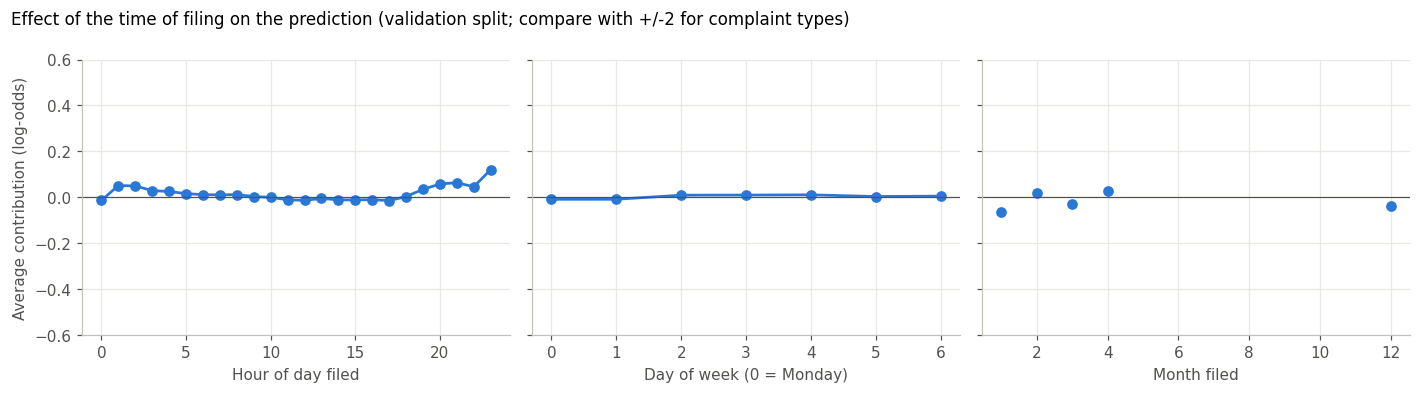

Months present in the validation split: [1, 2, 3, 4, 12] (the model saw all 12 months in training)


In [7]:
channel = cleaned_val["open_data_channel_type"]
by_channel = pd.DataFrame({"requests": channel.value_counts(), "average push (log-odds)": contribution["open_data_channel_type"].groupby(channel).mean(),
                           "really resolved within 7 days": pd.Series(y, index=channel.index).groupby(channel).mean()}).sort_values("average push (log-odds)")
display(by_channel.style.format({"requests": "{:,}", "average push (log-odds)": "{:+.2f}", "really resolved within 7 days": "{:.1%}"}))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, (feature, label, ticks) in zip(axes, [("hour", "Hour of day filed", None), ("weekday", "Day of week (0 = Monday)", None), ("month", "Month filed", None)]):
    effect = contribution[feature].groupby(cleaned_val[feature]).mean()
    ax.plot(effect.index, effect.values, marker="o", color=BLUE, linewidth=1.8 if feature != "month" else 0)   # months are separate points
    ax.axhline(0, color=INK, linewidth=0.8)
    ax.set_xlabel(label)
axes[0].set_ylabel("Average contribution (log-odds)")
axes[0].set_ylim(-0.6, 0.6)
fig.suptitle("Effect of the time of filing on the prediction (validation split; compare with +/-2 for complaint types)", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "08_other_feature_effects.png")
plt.show()
validation_months = sorted(cleaned_val.index.map(lambda i: pd.Timestamp(X_val.loc[i, "created_date"]).month).unique())
print("Months present in the validation split:", validation_months, "(the model saw all 12 months in training)")

**Reading it.**

- **The three real channels push almost equally** (+0.10 to +0.11 log-odds for online, mobile and phone). The real outcomes differ a lot between them (mobile 96.6% fast, online 86.6%, phone 69.9%), but that difference comes from *what kind* of request is filed through each channel, which the model already knows from the type and the place. The channel itself adds almost nothing.
- **An unknown channel pushes towards slow** (-0.45): 8.4% of the validation requests have no channel, and 66.5% of them were resolved within 7 days.
- **The time of filing barely changes any prediction.** The average effect of the hour is between -0.01 and +0.12 (late evening very slightly towards fast), of the weekday about 0, and of the month between -0.06 and +0.03 for the five months present in the validation split. Compare this with +2 and -2 for the complaint type: the time of filing would need to be 20 times larger to matter.
- **A caution about the month.** The model has seen each calendar month only once or twice (training covers about two years), so a month effect could be a coincidence of those years. It is tiny here, but it is the least trustworthy of the effects.

### 4.4 The strongest input: `location_type`, and what it stands for

`location_type` is as important as the complaint type (section 4.1), although it is an **optional** field in the API. The table shows why: in the training data, the place a request records is almost a fingerprint of **which city agency handles it**, and the agencies differ greatly in how fast they close requests. The same real place is written differently by different agencies: housing complaints (HPD) record `RESIDENTIAL BUILDING`; noise complaints (NYPD) record `Residential Building/House`.

The agency itself was dropped as a feature in Phase 4, because a person filing a request cannot supply it. The place carries much of the same information.

In [8]:
train = pd.read_parquet("../data/processed/train.parquet")           # training split only
common = train["location_type"].value_counts().head(9).index
rows = []
for place in common:
    part = train[train["location_type"] == place]
    shares = part["agency"].value_counts(normalize=True)
    rows.append({"location_type": place, "requests": len(part), "main agency": shares.index[0], "its share of the requests": shares.iloc[0],
                 "second agency": shares.index[1] if len(shares) > 1 else "", "its share ": shares.iloc[1] if len(shares) > 1 else 0.0,
                 "really resolved within 7 days": part[ft.TARGET].mean()})
place_table = pd.DataFrame(rows).set_index("location_type")
display(place_table.style.format({"requests": "{:,}", "its share of the requests": "{:.1%}", "its share ": "{:.1%}", "really resolved within 7 days": "{:.1%}"}))
print("Agencies: NYPD police; HPD housing; DSNY sanitation; DOT transport; DEP environment; DOB buildings; DPR parks; DHS homeless services; TLC taxis.")
by_agency = train.groupby("agency")[ft.TARGET].agg(requests="size", really_resolved_within_7d="mean").sort_values("requests", ascending=False).head(8)
display(by_agency.style.format({"requests": "{:,}", "really_resolved_within_7d": "{:.1%}"}))

,requests,main agency,its share of the requests,second agency,its share,really resolved within 7 days
location_type,,,,,,
STREET/SIDEWALK,"44,105",NYPD,98.5%,DHS,1.5%,99.8%
RESIDENTIAL BUILDING,"29,368",HPD,99.3%,DOHMH,0.6%,63.3%
RESIDENTIAL BUILDING/HOUSE,"17,929",NYPD,98.7%,DHS,1.3%,99.8%
Unknown,"16,619",DEP,47.0%,DOT,27.0%,73.5%
STREET,"12,610",DSNY,52.2%,DPR,24.9%,68.9%
SIDEWALK,"6,087",DSNY,76.1%,DOT,23.6%,80.8%
STORE/COMMERCIAL,"2,040",NYPD,90.4%,DHS,9.6%,99.2%
PARK,"1,309",DPR,100.0%,,0.0%,49.0%
CLUB/BAR/RESTAURANT,"1,241",NYPD,100.0%,,0.0%,100.0%


Agencies: NYPD police; HPD housing; DSNY sanitation; DOT transport; DEP environment; DOB buildings; DPR parks; DHS homeless services; TLC taxis.


,requests,really_resolved_within_7d
agency,,
NYPD,"65,452",100.0%
HPD,"29,157",63.6%
DSNY,"12,496",88.3%
DOT,"8,169",74.2%
DEP,"7,812",85.2%
DPR,"4,528",39.1%
DOB,"4,000",43.1%
DOHMH,"3,259",64.3%


**Reading it.**

- **The place is a fingerprint of the agency.** `STREET/SIDEWALK` (44,105 training requests) is 98.5% police (NYPD) requests, `RESIDENTIAL BUILDING/HOUSE` is 98.7% police, but `RESIDENTIAL BUILDING` (29,368) is 99.3% housing (HPD) requests. `PARK` is 100% parks department (DPR). The unknown place belongs mainly to DEP (47.0%) and DOT (27.0%) requests (and 24% DOB, not shown).
- **The agencies differ greatly in speed.** Police requests (65,452, the largest group) are 100.0% resolved within 7 days; housing requests 63.6%; buildings (DOB) 43.1%; parks (DPR) 39.1%. So a model that can tell which agency handles a request already knows a lot about how fast it will be closed.
- **Why this matters.** The agency was dropped as a feature in Phase 4 because a person filing a request cannot supply it. The place brings much of the same information back, and it is the model's strongest input. That is legitimate (the place is something the filer can give), but it has two consequences:
  1. The strongest feature is partly a **record-keeping habit of each agency**: the same kind of room is written `Residential Building/House` by the police and `RESIDENTIAL BUILDING` by the housing department.
  2. The API's `location_type` must be sent **the way 311 records it for that complaint type**. The next check shows how much the spelling matters.

**A check: the spelling of the place decides the answer.** Because the model reads `location_type` as a fingerprint of the handling agency, the same request can get a very different answer when only the place is written differently. The table sends complaint types with the place written in the different ways the city's data uses (borough Brooklyn, channel phone, same time; the saved final model).

In [1]:
import sys
import joblib
import pandas as pd
sys.path.insert(0, "..")

final_model = joblib.load("../models/model.joblib")
base = {"borough": "BROOKLYN", "open_data_channel_type": "PHONE", "created_at": "2026-02-10T14:00:00"}
cases = [("Noise - Residential", ["Residential Building/House", "RESIDENTIAL BUILDING", "Street/Sidewalk"]),
         ("Unsanitary Condition", ["RESIDENTIAL BUILDING", "Residential Building/House", "Street/Sidewalk"]),
         ("Illegal Parking", ["Street/Sidewalk", "RESIDENTIAL BUILDING"]),
         ("Heat/Hot Water", ["RESIDENTIAL BUILDING", "Residential Building/House"])]
rows = []
for complaint, places in cases:
    for place in places:
        request = {**base, "complaint_type": complaint, "location_type": place}
        probability = float(final_model.predict_proba(pd.DataFrame([request]))[0, 1])
        rows.append({"complaint_type": complaint, "location_type as sent": place, "probability": probability,
                     "predicted": "resolved within 7 days" if probability > 0.5 else "NOT resolved within 7 days"})
display(pd.DataFrame(rows).style.format({"probability": "{:.3f}"}).hide(axis="index"))

complaint_type,location_type as sent,probability,predicted
Noise - Residential,Residential Building/House,0.996,resolved within 7 days
Noise - Residential,RESIDENTIAL BUILDING,0.736,resolved within 7 days
Noise - Residential,Street/Sidewalk,0.999,resolved within 7 days
Unsanitary Condition,RESIDENTIAL BUILDING,0.447,NOT resolved within 7 days
Unsanitary Condition,Residential Building/House,0.986,resolved within 7 days
Unsanitary Condition,Street/Sidewalk,0.997,resolved within 7 days
Illegal Parking,Street/Sidewalk,1.000,resolved within 7 days
Illegal Parking,RESIDENTIAL BUILDING,0.867,resolved within 7 days
Heat/Hot Water,RESIDENTIAL BUILDING,0.998,resolved within 7 days
Heat/Hot Water,Residential Building/House,0.998,resolved within 7 days


**Reading it.** The same "Unsanitary Condition" request is predicted **slow** (probability 0.447) when the place is `RESIDENTIAL BUILDING`, the housing department's wording, and **fast** (0.986) when it is `Residential Building/House`, the police wording. A noise complaint written with the housing wording drops from 0.996 to 0.736. For heat and hot water the wording does not matter (0.998 either way), because the complaint type alone decides.

So the model does not really "understand" the building: it recognises the way a given agency records its requests. For a real user this means: *send the place exactly as the 311 system records it for that kind of complaint.* The API documentation (`/docs`) says so, and the API adds a warning when the place is missing.

## 5. Why one request gets its prediction

The same method explains one request at a time. The model starts from a **base value** (its average answer, in log-odds). Each feature then adds or subtracts a contribution. The sum is the request's **log-odds**, which converts to the probability:

`probability = 1 / (1 + exp(-log-odds))`

The five sample requests below are the real validation requests of `data/sample_requests.json`, the same ones used to test the API. The table shows, for each, the value the model used for each feature (after cleaning) and its contribution.

validation_example_1: Blocked Driveway (STATEN ISLAND, PHONE)  ->  probability 0.999, predicted resolved within 7 days, true label 1
   base value +0.82;  location_type = STREET/SIDEWALK (+4.24);  complaint_type = BLOCKED DRIVEWAY (+1.39);  latitude = 40.561436 (+0.12);  open_data_channel_type = PHONE (+0.12);  all other features +0.12;  log-odds +6.80
validation_example_2: Illegal Parking (QUEENS, ONLINE)  ->  probability 0.999, predicted resolved within 7 days, true label 1
   base value +0.82;  location_type = STREET/SIDEWALK (+4.24);  complaint_type = ILLEGAL PARKING (+1.92);  month = 3 (-0.26);  borough = QUEENS (+0.06);  all other features +0.11;  log-odds +6.88
validation_example_3: Snow or Ice (BROOKLYN, ONLINE)  ->  probability 0.643, predicted resolved within 7 days, true label 1
   base value +0.82;  location_type = STREET (-0.51);  complaint_type = SNOW OR ICE (+0.45);  borough = BROOKLYN (-0.31);  open_data_channel_type = ONLINE (+0.16);  all other features -0.02;  log-odd

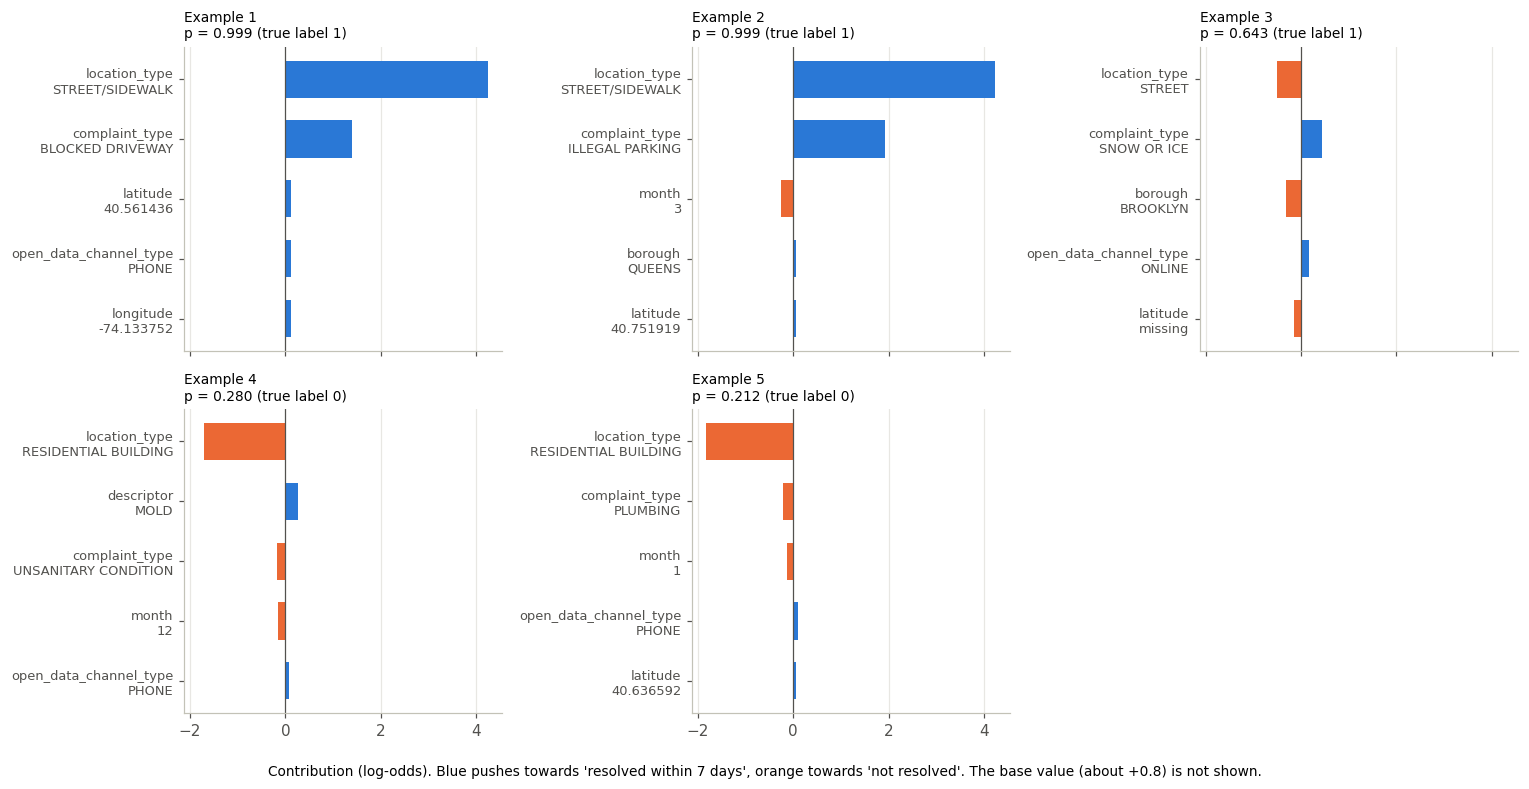

In [9]:
samples = json.loads(Path("../data/sample_requests.json").read_text())["valid_requests"]
explained = []
for item in samples:
    request = pd.DataFrame([item["request"]])
    cleaned_one, parts, bias_one = tr.xgb_contributions(model, request)
    log_odds = parts.iloc[0].sum() + bias_one
    probability = 1 / (1 + np.exp(-log_odds))
    assert abs(probability - model.predict_proba(request)[0, 1]) < 1e-6
    explained.append({"name": item["name"], "request": item["request"], "cleaned": cleaned_one.iloc[0], "parts": parts.iloc[0], "bias": bias_one,
                      "log_odds": log_odds, "probability": probability, "true_label": item["true_label"]})

for e in explained:
    top3 = e["parts"].reindex(e["parts"].abs().sort_values(ascending=False).index).head(4)
    print(f"{e['name']}: {e['request']['complaint_type']} ({e['request']['borough']}, {e['request']['open_data_channel_type']})  ->  "
          f"probability {e['probability']:.3f}, predicted {'resolved within 7 days' if e['probability'] > 0.5 else 'NOT resolved within 7 days'}, true label {e['true_label']}")
    print("   base value %+.2f;  " % e["bias"] + ";  ".join(f"{f} = {e['cleaned'][f]} ({v:+.2f})" for f, v in top3.items()) +
          f";  all other features {e['parts'].drop(top3.index).sum():+.2f};  log-odds {e['log_odds']:+.2f}")

fig, axes = plt.subplots(2, 3, figsize=(14, 7.2), sharex=True)
axes[1, 2].axis("off")
for ax, e in zip(axes.ravel(), explained):
    parts = e["parts"].reindex(e["parts"].abs().sort_values(ascending=False).index).head(5)
    labels = [f"{f}\n{'missing' if pd.isna(e['cleaned'][f]) else str(e['cleaned'][f])[:22]}" for f in parts.index]
    ax.barh(range(len(parts)), parts.values, color=[ORANGE if v < 0 else BLUE for v in parts.values], height=0.62)
    ax.set_yticks(range(len(parts)), labels, fontsize=8.5)
    ax.invert_yaxis()
    ax.axvline(0, color=INK, linewidth=0.8)
    ax.set_title(f"{e['name'].replace('validation_example_', 'Example ')}\np = {e['probability']:.3f} (true label {e['true_label']})", loc="left", fontsize=9)
    ax.grid(axis="y", visible=False)
fig.supxlabel("Contribution (log-odds). Blue pushes towards 'resolved within 7 days', orange towards 'not resolved'. The base value (about +0.8) is not shown.", fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "08_sample_explanations.png")
plt.show()

**Reading the five examples.** The base value of +0.82 (a probability of about 0.69) is the model's starting point before it looks at the request.

- **Examples 1 and 2** (Blocked Driveway, Illegal Parking): the place `STREET/SIDEWALK` adds +4.24 and the complaint type adds +1.4 and +1.9. Everything else adds less than 0.4 net. The probability is 0.999 for both: requests of this kind are almost always closed within days.
- **Example 3** (Snow or Ice): the pushes nearly cancel. The place `STREET` pushes -0.51, the borough Brooklyn -0.31, the complaint type +0.45, the channel +0.16. The sum is +0.59, a probability of 0.643: **predicted fast, and correct, but close to the cut-off**, so it is an uncertain call.
- **Example 4** (Unsanitary Condition): the place `RESIDENTIAL BUILDING` pushes -1.71 (the housing agency's way of recording the place, section 4.4), the descriptor "MOLD" +0.27, the complaint type -0.18, the month (December) -0.16. The sum is -0.95, a probability of 0.280: **predicted slow, and correct**.
- **Example 5** (Plumbing): the place `RESIDENTIAL BUILDING` pushes -1.82, the complaint type -0.22. The probability is 0.212: **predicted slow, and correct**.

**What this shows.** For a typical request, one or two inputs decide the answer (the place and the type) and the rest add very little. That makes the model easy to explain to a non-specialist: *"the model recognises the kind of request and the service that handles it, and remembers how fast that service usually is."*

## 6. How far the probability can be trusted

The API returns a probability. Two questions decide how to read it: *is it a real frequency?* and *which cut-off turns it into a yes or no?*

### 6.1 Is the probability a real frequency?

Validation requests are grouped by the probability the model gave them. For each group, the table compares the model's average probability with the share that were **really** resolved within 7 days. A model whose probabilities are exact frequencies would have the two columns equal.

,requests,average_probability,really_resolved_within_7d,difference (points)
0.0 to 0.1,518,0.038,0.071,+3.3
0.1 to 0.2,"1,412",0.168,0.291,+12.3
0.2 to 0.3,"2,761",0.236,0.315,+7.8
0.3 to 0.4,864,0.353,0.480,+12.8
0.4 to 0.5,638,0.447,0.566,+11.9
0.5 to 0.6,626,0.548,0.657,+10.8
0.6 to 0.7,917,0.655,0.822,+16.7
0.7 to 0.8,"1,116",0.751,0.872,+12.1
0.8 to 0.9,"1,882",0.849,0.922,+7.3
0.9 to 1.0,"19,096",0.991,0.987,-0.4


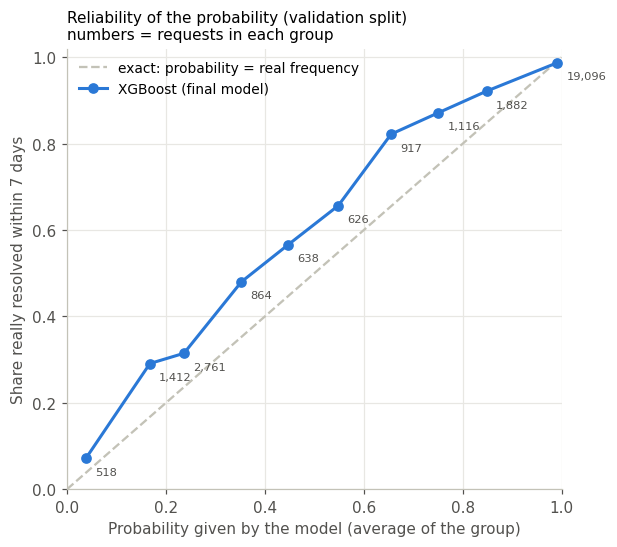

64% of the validation requests get a probability above 0.9, and 98.7% of them were really resolved within 7 days.


In [10]:
edges = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
groups_p = pd.cut(xgb_probability, edges, include_lowest=True)
calibration = pd.DataFrame({"p": xgb_probability, "y": y}).groupby(groups_p, observed=True).agg(
    requests=("y", "size"), average_probability=("p", "mean"), really_resolved_within_7d=("y", "mean"))
calibration["difference (points)"] = (calibration["really_resolved_within_7d"] - calibration["average_probability"]) * 100
calibration.index = [f"{a:.1f} to {b:.1f}" for a, b in zip(edges[:-1], edges[1:])][: len(calibration)]
display(calibration.style.format({"requests": "{:,}", "average_probability": "{:.3f}", "really_resolved_within_7d": "{:.3f}", "difference (points)": "{:+.1f}"}))

fig, ax = plt.subplots(figsize=(5.8, 5.2))
ax.plot([0, 1], [0, 1], color=GREY, linestyle="--", label="exact: probability = real frequency")
ax.plot(calibration["average_probability"], calibration["really_resolved_within_7d"], marker="o", color=BLUE, linewidth=2, label="XGBoost (final model)")
for _, row in calibration.iterrows():
    ax.annotate(f"{int(row['requests']):,}", (row["average_probability"], row["really_resolved_within_7d"]), textcoords="offset points", xytext=(6, -11), fontsize=7.5, color=INK)
ax.set_xlabel("Probability given by the model (average of the group)")
ax.set_ylabel("Share really resolved within 7 days")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.set_title("Reliability of the probability (validation split)\nnumbers = requests in each group", loc="left", fontsize=10)
ax.legend(loc="upper left", frameon=False, fontsize=9)
fig.savefig(FIG_DIR / "08_calibration.png")
plt.show()
share_high = (xgb_probability > 0.9).mean()
print(f"{share_high:.0%} of the validation requests get a probability above 0.9, and {calibration.iloc[-1]['really_resolved_within_7d']:.1%} of them were really resolved within 7 days.")

**Reading it.**

- **The probability is a score, not an exact chance.** In the middle of the range it is too low. Requests scored between 0.6 and 0.7 (average 0.655) were really resolved within 7 days 82.2% of the time; between 0.1 and 0.2 (average 0.168), 29.1%. For every group between 0.1 and 0.9 the real share is 7 to 17 points higher than the probability. Only at the top, above 0.9, do the two agree: that group is 64% of all requests and 98.7% of them were really fast.
- **Why.** The model was trained with `scale_pos_weight` 0.4556, which makes the common class (resolved within 7 days) count less, so that the slow requests are not ignored. That lowers all the probabilities compared with real frequencies. It helps to find slow requests, but it means the number should be read as a score.
- **How to read it.** A higher probability does mean a request is more likely to be fast (ROC-AUC 0.943). The cut-off of 0.5 on this scale corresponds to a real fast rate of roughly 57% to 66% (the groups 0.4 to 0.5 and 0.5 to 0.6 were 56.6% and 65.7% fast). So "predicted slow" means "probably under about 60% likely to be fast", not "under 50%".
- **A possible improvement, not done:** a calibration step could turn the score into an exact probability.

### 6.2 Which cut-off? What each choice costs

The model predicts "resolved within 7 days" when the probability is above the cut-off. A **higher** cut-off flags more requests as slow: it catches more of the slow ones (higher recall of class 0) but raises more false alarms (lower precision). A lower cut-off does the opposite. The table and chart show the whole trade-off on the validation split. This is **descriptive**: the deployed cut-off stays 0.5, and nothing here is used to tune it. Staff who want a different balance can use the probability returned by the API.

,requests flagged as slow,share of all requests flagged,slow requests caught (recall 0),flags that are right (precision 0),false alarms,macro F1,accuracy
cut-off,,,,,,,
0.20,"1,930",6.5%,29.6%,76.8%,448,0.676,0.867
0.30,"4,691",15.7%,67.4%,71.9%,"1,317",0.818,0.901
0.40,"5,555",18.6%,76.4%,68.8%,"1,732",0.832,0.902
0.50,"6,193",20.8%,81.9%,66.2%,"2,093",0.835,0.899
0.60,"6,819",22.9%,86.2%,63.3%,"2,504",0.831,0.893
0.70,"7,736",25.9%,89.4%,57.9%,"3,258",0.811,0.873
0.80,"8,852",29.7%,92.3%,52.2%,"4,231",0.783,0.845


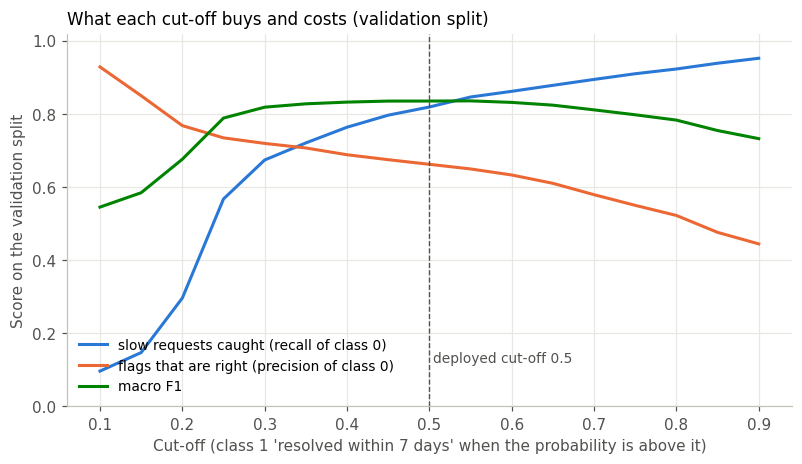

In [11]:
rows = []
for cutoff in np.round(np.arange(0.10, 0.91, 0.05), 2):
    r = tr.evaluate_probability(y_val, xgb_probability, cutoff)
    flagged = r["actual0_pred0"] + r["actual1_pred0"]
    rows.append({"cut-off": cutoff, "requests flagged as slow": flagged, "share of all requests flagged": flagged / len(y_val),
                 "slow requests caught (recall 0)": r["recall_0"], "flags that are right (precision 0)": r["precision_0"],
                 "false alarms": r["actual1_pred0"], "macro F1": r["macro_f1"], "accuracy": r["accuracy"]})
tradeoff = pd.DataFrame(rows).set_index("cut-off")
display(tradeoff.loc[[0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80]].style.format_index("{:.2f}").format(
    {"requests flagged as slow": "{:,}", "share of all requests flagged": "{:.1%}", "slow requests caught (recall 0)": "{:.1%}",
     "flags that are right (precision 0)": "{:.1%}", "false alarms": "{:,}", "macro F1": "{:.3f}", "accuracy": "{:.3f}"}))

fig, ax = plt.subplots(figsize=(8.5, 4.4))
for column, color, label in [("slow requests caught (recall 0)", BLUE, "slow requests caught (recall of class 0)"),
                             ("flags that are right (precision 0)", ORANGE, "flags that are right (precision of class 0)"),
                             ("macro F1", GREEN, "macro F1")]:
    ax.plot(tradeoff.index, tradeoff[column], color=color, linewidth=2, label=label)
ax.axvline(0.5, color=INK, linewidth=0.9, linestyle="--")
ax.text(0.505, 0.12, "deployed cut-off 0.5", color=INK, fontsize=9)
ax.set_xlabel("Cut-off (class 1 'resolved within 7 days' when the probability is above it)")
ax.set_ylabel("Score on the validation split")
ax.set_ylim(0, 1.02)
ax.set_title("What each cut-off buys and costs (validation split)", loc="left", fontsize=11)
ax.legend(loc="lower left", frameon=False, fontsize=9)
fig.savefig(FIG_DIR / "08_threshold_tradeoff.png")
plt.show()

**Reading it.**

- **At the deployed cut-off of 0.5** the model flags 20.8% of the requests as slow, catches 81.9% of the really slow ones, is right for 66.2% of its flags, and raises 2,093 false alarms.
- **Macro F1 is flat between 0.4 and 0.6** (0.832, 0.835, 0.831) and falls quickly beyond, so 0.5 sits near the best balance of the two kinds of mistake.
- **A higher cut-off is a choice about cost.** From 0.5 to 0.7 the model catches 7.5 points more slow requests (81.9% to 89.4%), but only 57.9% of its flags are right (from 66.2%), and there are 1,165 more false alarms (3,258). If missing a slow request is much worse than a false alarm, staff can use the probability returned by the API with a higher cut-off; if false alarms are costly, a lower one (0.3: 67.4% caught, 71.9% of flags right).

## 7. Where the model is weaker

A model that is right 90% of the time can still be much weaker for some requests. Validation split, the 14 most common complaint types, with the share of requests that are really slow, the share of those that the model catches, and its overall accuracy for the type. Then the requests whose complaint type the model does not know ("Other").

In [12]:
common = pd.DataFrame({"type": cleaned_val["complaint_type"].to_numpy(), "y": y, "pred": xgb_class})
by_type = common.groupby("type").apply(lambda g: pd.Series({
    "requests": len(g), "really slow (class 0)": (g["y"] == 0).mean(),
    "slow requests caught": ((g["pred"] == 0) & (g["y"] == 0)).sum() / max((g["y"] == 0).sum(), 1),
    "accuracy": (g["pred"] == g["y"]).mean()}), include_groups=False)
def inside_auc(name):
    g = common[common["type"] == name]
    if (g["y"] == 0).sum() < 30 or (g["y"] == 1).sum() < 30:
        return np.nan                                                    # one class (almost) absent: the question has no meaning
    return roc_auc_score(g["y"], xgb_probability[(common["type"] == name).to_numpy()])
by_type["ROC-AUC inside the type"] = [inside_auc(name) for name in by_type.index]
by_type = by_type.sort_values("requests", ascending=False)
fmt_type = {"requests": "{:,.0f}", "really slow (class 0)": "{:.1%}", "slow requests caught": "{:.1%}", "accuracy": "{:.1%}", "ROC-AUC inside the type": "{:.2f}"}
display(by_type.head(14).style.format(fmt_type, na_rep="-"))

mixed = by_type[(by_type["requests"] >= 300) & by_type["really slow (class 0)"].between(0.2, 0.8)].sort_values("requests", ascending=False)
print("Complaint types with a real mixture of fast and slow requests (20% to 80% slow, at least 300 requests): where the model has most to do")
display(mixed.style.format(fmt_type, na_rep="-"))
unseen = by_type.loc[["Other"]]
print("Requests whose complaint type the model does not know (grouped as 'Other'):")
display(unseen.style.format(fmt_type, na_rep="-"))
overall_ranking = pd.Series({"all known types": roc_auc_score(y[(common['type'] != 'Other').to_numpy()], xgb_probability[(common['type'] != 'Other').to_numpy()]),
                             "Other types": roc_auc_score(y[(common['type'] == 'Other').to_numpy()], xgb_probability[(common['type'] == 'Other').to_numpy()])})
print("ROC-AUC on known types and on 'Other' (validation):", overall_ranking.round(3).to_dict())

# How well does the model separate fast from slow INSIDE a complaint type? (types with at least 30 requests of each class)
inside = by_type["ROC-AUC inside the type"].dropna()
weights = by_type.loc[inside.index, "requests"]
print(f"\nROC-AUC inside a complaint type (0.5 = no better than a coin flip), for the {len(inside)} types with at least 30 slow and 30 fast requests:")
print(f"  lowest {inside.min():.2f} ({inside.idxmin()}), highest {inside.max():.2f} ({inside.idxmax()}), median {inside.median():.2f}, "
      f"weighted by number of requests {np.average(inside, weights=weights):.2f}; {int((inside < 0.6).sum())} of {len(inside)} types are below 0.60")

,requests,really slow (class 0),slow requests caught,accuracy,ROC-AUC inside the type
type,,,,,
HEAT/HOT WATER,"4,754",0.3%,0.0%,99.7%,-
ILLEGAL PARKING,"4,445",0.0%,0.0%,100.0%,-
NOISE - RESIDENTIAL,"3,206",0.0%,0.0%,100.0%,-
BLOCKED DRIVEWAY,"1,568",0.0%,0.0%,100.0%,-
SNOW OR ICE,"1,324",12.1%,8.1%,88.3%,0.58
STREET CONDITION,"1,011",21.0%,0.9%,79.2%,0.51
UNSANITARY CONDITION,896,73.5%,100.0%,73.5%,0.57
PLUMBING,745,59.5%,98.4%,63.1%,0.72
NOISE - STREET/SIDEWALK,603,0.0%,0.0%,100.0%,-


Complaint types with a real mixture of fast and slow requests (20% to 80% slow, at least 300 requests): where the model has most to do


,requests,really slow (class 0),slow requests caught,accuracy,ROC-AUC inside the type
type,,,,,
STREET CONDITION,"1,011",21.0%,0.9%,79.2%,0.51
UNSANITARY CONDITION,896,73.5%,100.0%,73.5%,0.57
PLUMBING,745,59.5%,98.4%,63.1%,0.72
PAINT/PLASTER,530,58.3%,98.7%,58.3%,0.61
DOOR/WINDOW,436,79.4%,100.0%,79.4%,0.55
WATER LEAK,381,69.3%,100.0%,69.3%,0.45
GENERAL,323,75.9%,100.0%,75.9%,0.62


Requests whose complaint type the model does not know (grouped as 'Other'):


,requests,really slow (class 0),slow requests caught,accuracy,ROC-AUC inside the type
type,,,,,
Other,205,58.5%,50.0%,51.7%,0.55


ROC-AUC on known types and on 'Other' (validation): {'all known types': 0.944, 'Other types': 0.547}

ROC-AUC inside a complaint type (0.5 = no better than a coin flip), for the 25 types with at least 30 slow and 30 fast requests:
  lowest 0.45 (ELEVATOR), highest 0.82 (NOISE), median 0.62, weighted by number of requests 0.61; 10 of 25 types are below 0.60


**Reading it.**

- **Most requests are easy.** For the types that are almost always fast (heat and hot water, illegal parking, residential and street noise, blocked driveway, abandoned vehicle) the accuracy is 99.7% to 100%. Together with the other near-certain cases, 64% of all validation requests get a probability above 0.9.
- **Inside a complaint type the model separates fast from slow only modestly.** Its ROC-AUC inside a type (0.5 is a coin flip) has a median of 0.62 over the 25 types that have enough fast and slow requests, and 0.61 weighted by number of requests; 10 of the 25 types are below 0.60. The lowest are Elevator (0.45), Water Leak (0.45), Street Condition (0.51), Door/Window (0.55) and Unsanitary Condition (0.57); the best are Noise (0.82), General Construction/Plumbing (0.77), Electric (0.77) and Sidewalk Condition (0.74). What the model really knows is *what kind of request this is*; it can rarely tell which request of a given kind will be slow. That is why the complaint-type-only baseline already reaches macro F1 0.801 and XGBoost adds 3.4 points (0.835).
- **Blind spots: mostly-fast types that are sometimes slow.** Street Condition is really slow for 21.0% of its requests and the model catches 0.9% of them; Snow or Ice 12.1% slow, 8.1% caught; Water System 19.9% slow, 10.1% caught; Traffic Signal 7.5% slow, 0% caught. The model predicts "fast" for nearly all of them.
- **The opposite error: mostly-slow housing types.** The model predicts 94.5% to 100% of the Unsanitary Condition, Plumbing, Paint/Plaster, Door/Window, Water Leak and General requests as slow, so its accuracy for these types is about the share that are really slow (58% to 79%). The 21% to 42% that were resolved within 7 days are nearly all false alarms.
- **Unknown complaint types.** For the 205 validation requests whose type is not known to the model ("Other", 0.7% of requests) the accuracy is 51.7% and the ROC-AUC 0.55: practically random. The API warns when this happens. In the forward test set, the city's renamed water and sewer types raised this group to 3.1% of the requests.
- **Over time.** The scores fell from validation (macro F1 0.835) to the forward test set (0.807), mostly through less precise "slow" flags (precision 66.2% to 58.1%); notebook 05, section 8 gives the reasons.

### What if the optional fields are missing?

`descriptor`, `location_type`, `incident_zip`, `latitude` and `longitude` are optional in the API. The table removes them from the validation requests (as the API would, when a caller leaves them out) and scores the same model again. Nothing is refitted.

In [13]:
rows = {}
scenarios = [("nothing missing", []), ("without location_type", ["location_type"]), ("without descriptor", ["descriptor"]),
             ("without incident_zip", ["incident_zip"]), ("without latitude and longitude", ["latitude", "longitude"]),
             ("without descriptor and location_type", ["descriptor", "location_type"]),
             ("without all five optional fields", ["descriptor", "location_type", "incident_zip", "latitude", "longitude"])]
probabilities = {}
for label, columns in scenarios:
    X_missing = X_val.copy()
    if columns:
        X_missing[columns] = None
    probabilities[label] = model.predict_proba(X_missing)[:, 1]
    r = tr.evaluate_probability(y_val, probabilities[label])
    rows[label] = {"macro F1": r["macro_f1"], "ROC-AUC": r["roc_auc"], "slow requests caught (recall 0)": r["recall_0"],
                   "flags that are right (precision 0)": r["precision_0"], "accuracy": r["accuracy"]}
missing_table = pd.DataFrame(rows).T
display(missing_table.style.format("{:.3f}"))

focus = ["UNSANITARY CONDITION", "PLUMBING", "PAINT/PLASTER", "DOOR/WINDOW", "WATER LEAK", "GENERAL"]
slow_mask = (y_val.to_numpy() == 0)
focus_rows = {}
for name in focus:
    inside_type = (cleaned_val["complaint_type"] == name).to_numpy() & slow_mask
    focus_rows[name] = {"really slow requests": int(inside_type.sum()),
                        "caught, location_type given": (xgb_probability[inside_type] <= 0.5).mean(),
                        "caught, location_type missing": (probabilities["without location_type"][inside_type] <= 0.5).mean()}
print("Slow requests of the mostly-slow housing types: share that the model catches with and without location_type")
display(pd.DataFrame(focus_rows).T.style.format({"really slow requests": "{:,.0f}", "caught, location_type given": "{:.1%}", "caught, location_type missing": "{:.1%}"}))

,macro F1,ROC-AUC,slow requests caught (recall 0),flags that are right (precision 0),accuracy
nothing missing,0.835,0.943,0.819,0.662,0.899
without location_type,0.652,0.913,0.277,0.649,0.854
without descriptor,0.820,0.939,0.753,0.662,0.894
without incident_zip,0.833,0.943,0.768,0.687,0.902
without latitude and longitude,0.835,0.944,0.821,0.661,0.899
without descriptor and location_type,0.603,0.899,0.191,0.632,0.845
without all five optional fields,0.581,0.897,0.151,0.691,0.846


Slow requests of the mostly-slow housing types: share that the model catches with and without location_type


,really slow requests,"caught, location_type given","caught, location_type missing"
UNSANITARY CONDITION,659,100.0%,8.5%
PLUMBING,443,98.4%,5.0%
PAINT/PLASTER,309,98.7%,0.0%
DOOR/WINDOW,346,100.0%,0.0%
WATER LEAK,264,100.0%,0.0%
GENERAL,245,100.0%,27.8%


**Reading it.**

- **Leaving out `location_type` is the one omission that really hurts.** Macro F1 falls from 0.835 to 0.652, and the share of slow requests the model catches from 81.9% to 27.7%. The ROC-AUC falls much less (0.943 to 0.913): the ranking is damaged, but the cut-off no longer fits.
- **Why so much.** A missing place is read as the category `Unknown`, which in the training data belongs mostly to DEP, DOT and DOB requests (73.5% of them resolved within 7 days). A housing complaint with an unknown place therefore looks like nothing the model was trained on, and the model stops flagging it: of the really slow Unsanitary Condition requests it catches 100% with the place and 8.5% without; Plumbing 98.4% and 5.0%; Paint/Plaster 98.7% and 0%; Door/Window and Water Leak 100% and 0%.
- **The other optional fields matter little.** Without the `descriptor` macro F1 falls by 1.5 points (to 0.820); without the ZIP code by 0.2 points; without latitude and longitude it does not change at all (0.835). With all five optional fields missing, macro F1 is 0.581 and only 15.1% of the slow requests are caught.
- **What the API does about it.** `location_type` stays optional, as the specification says, but the response now carries a warning when it is missing, and `/docs` marks it as the most important input.

## 8. Summary for the report

### The final model and why

- **The final model is XGBoost alone** (600 trees of depth 8, learning rate 0.05, extra attention to the slow requests, cut-off 0.5), fitted on the training split only.
- **Why not the stack.** The course instructor's rule is to use XGBoost when the stacking model is not as good. It is not: on validation the best stack has macro F1 0.8339 against 0.8351 and the same ROC-AUC, and on the forward test set the two are level (0.8074 against 0.8070). The stack is also 11 times larger and more than twice as slow (section 2).
- **Why the stack did not help.** The models inside it make almost the same predictions (probabilities 0.93 to 0.99 correlated), almost all of the information sits in two columns that every model reads in the same way, and most of the first gap was only the position of the cut-off. The stacking classifier was built and compared as required (notebooks 04 and 05); the honest result is that it did not beat its best member.

### How well it works

| Data | Macro F1 | ROC-AUC | Slow requests caught | Flags that are right |
| --- | --- | --- | --- | --- |
| Validation split (29,830 requests) | 0.8351 | 0.9433 | 81.9% | 66.2% |
| Forward test set (12,069 requests, never used to choose anything) | 0.8070 | 0.9330 | 84.0% | 58.1% |
| Original test split (29,831 requests, scored in Phase 6) | 0.8258 | 0.9369 | 83.4% | 64.1% |
| For comparison: complaint type only, forward test | 0.7796 | 0.9201 | 65.7% | 60.6% |

"Slow requests caught" is the recall of class 0 (not resolved within 7 days), and "flags that are right" its precision. The forward test set is the cleanest number; it contains closed requests only, so it is somewhat easier than reality (section 2 of notebook 05).

### What the model learned

- It recognises **what kind of request was reported and which city service handles it**: the complaint type and the place together carry 81% to 93% of the importance (section 4.1). Police-handled requests (parking, noise, driveways) and heat complaints are almost always closed within 7 days; housing repair requests (plumbing, paint, doors and windows, unsanitary conditions) are the slow ones.
- **Where and when** a request was filed hardly matters: coordinates, borough, ZIP code and the time of filing together carry about 5% (section 4.1, 4.3).
- The place (`location_type`) is the strongest input because it is a fingerprint of the handling agency (section 4.4). Written the wrong way, it changes the prediction completely (section 4.4, check).

### How to read a prediction

- The **probability** is a score: higher means more likely to be resolved within 7 days. It is **not an exact chance**; in the middle of the range the real share is 7 to 17 points higher than the number (section 6.1).
- The **class** is "resolved within 7 days" when the probability is above 0.5. Staff who want to flag more slow requests can use a higher cut-off, at the price of more false alarms (section 6.2).
- Any **warning** in the response means a value was missing or unknown and the prediction is less reliable. The most important case is a missing `location_type`.
- For one request, the contributions of section 5 show why: usually one or two inputs (the type and the place) decide the answer.

### What the model cannot do

- It cannot tell which request of a mixed kind will be slow: inside a complaint type its ROC-AUC has a median of only 0.62, and it almost never flags Street Condition, Snow or Ice or Traffic Signal requests as slow (section 7).
- It does not know new complaint types (it is practically random on them), and the city renames types from time to time.
- It needs `location_type` for good results, and its strongest input is a record-keeping habit of the agencies, not a physical property of the problem.
- It uses only information available when the request is filed. It cannot know about an agency's workload, the weather, or what happens after the request.
- The sample holds closed requests only (a 1-in-48 sample), so the newest months look a little easier than they are.

### In one paragraph

*The final model is a single XGBoost classifier. It looks at the complaint type, the place, and a few other details of a 311 request, and recognises which city service will handle it and how fast that service usually is: police and heating requests are closed within days, housing repairs often take longer. It is right for about 90% of requests and finds about 82% of the ones that take more than a week, but it is much better at knowing the kind of request than at telling which request of a given kind will be late. A stacking model that combined four different models was built and tested, and did no better, so the simpler single model was chosen, as the course instructor's rule says.*

## 9. The saved files and the check that the saved model works

The final model is saved as `models/model.joblib` (version 3.0; the stack v2 stays as `models/model_stack_v2.joblib` and the Phase 6 stack as `models/model_v1.joblib`; none of these is in Git). The description files are refreshed, and the five sample requests get the answers of this model. The fresh-process check is run again.

In [14]:
from datetime import datetime

validation_table = pd.DataFrame({
    "XGBoost alone": final_scores | {"role": "final model (version 3.0)"},
    "Stack v2": tr.evaluate_probability(y_val, stack_probability, 0.61) | {"role": "stacking classifier compared with it (version 2.0)"},
    "Stack v1": tr.evaluate(joblib.load("../models/model_v1.joblib"), X_val, y_val)[0] | {"role": "first stacking classifier (version 1.0)"},
    "Baseline: complaint type only": tr.evaluate(scratch["Baseline: complaint type only"], X_val, y_val)[0] | {"role": "baseline"},
    "Baseline: majority class": tr.evaluate(scratch["Baseline: majority class"], X_val, y_val)[0] | {"role": "baseline"},
}).T
validation_table.index.name = "model"
validation_table = validation_table[["role"] + [c for c in validation_table.columns if c != "role"]]
validation_table.to_csv("../reports/final_model_validation.csv")
assert abs(float(validation_table.loc["Stack v2", "macro_f1"]) - float(v2.loc["Stack v2", "macro_f1"])) < 1e-9
print("Saved ../reports/final_model_validation.csv (XGBoost alone, the two stacks and the baselines on the validation split)")

best_settings[tr.FINAL_KEY] = {"model": "XGBoost", "settings_from": "XGBoost", "decision_threshold": 0.5, "model_version": "3.0"}
Path("../reports/best_settings.json").write_text(json.dumps(best_settings, indent=2), encoding="utf-8")

joblib.dump(model, "../models/model.joblib")
MODEL_PATH = Path("../models/model.joblib")
size_mb = MODEL_PATH.stat().st_size / 1e6
sha256 = hashlib.sha256(MODEL_PATH.read_bytes()).hexdigest()
print(f"Saved ../models/model.joblib: {size_mb:.2f} MB (was 19.8 MB for the stack), SHA-256 {sha256[:16]}...")

# Sample requests: same five validation rows, answers of the new model
sample_file = json.loads(Path("../data/sample_requests.json").read_text())
for item in sample_file["valid_requests"]:
    request = pd.DataFrame([item["request"]])
    item["expected_probability_within_threshold"] = round(float(model.predict_proba(request)[0, 1]), 12)
    item["expected_predicted_class"] = int(model.predict(request)[0])
sample_file["decision_threshold"] = 0.5
sample_file["description"] = ("Raw requests in the format of the API (CLAUDE.md section 6), with the answers of the final model (XGBoost alone, version 3.0). "
                              "valid_requests come from the VALIDATION split (no test split was used); the predicted class is 1 when the probability is above "
                              "decision_threshold. invalid_requests must be rejected by the API with the status shown.")
Path("../data/sample_requests.json").write_text(json.dumps(sample_file, indent=2), encoding="utf-8")
display(pd.DataFrame([{"example": v["name"], "complaint_type": v["request"]["complaint_type"], "true label": v["true_label"],
                       "probability within 7 days": v["expected_probability_within_threshold"], "predicted class": v["expected_predicted_class"]}
                      for v in sample_file["valid_requests"]]).style.format({"probability within 7 days": "{:.4f}"}).hide(axis="index"))

Saved ../reports/final_model_validation.csv (XGBoost alone, the two stacks and the baselines on the validation split)
Saved ../models/model.joblib: 1.81 MB (was 19.8 MB for the stack), SHA-256 d5a5bedfd3d41cc2...


example,complaint_type,true label,probability within 7 days,predicted class
validation_example_1,Blocked Driveway,1,0.9989,1
validation_example_2,Illegal Parking,1,0.9990,1
validation_example_3,Snow or Ice,1,0.6426,1
validation_example_4,UNSANITARY CONDITION,0,0.2797,0
validation_example_5,PLUMBING,0,0.2125,0


In [15]:
latency_ms = tr.predict_one_ms(model, one_request, repeats=60)
print(f"One prediction: {latency_ms:.1f} ms (the stack v2 took {cost.loc['Stack v2', 'one prediction ms']:.0f} ms in the same session)")

versions = {"python": platform.python_version(), **{name: __import__("importlib.metadata", fromlist=["version"]).version(name) for name in
            ["scikit-learn", "xgboost", "pandas", "numpy", "joblib"]}}
meta = json.loads(Path("../models/model_meta.json").read_text())
old_version = meta["model_version"]
settings = best_settings["XGBoost"]
meta.update({"model_name": "CivicAI XGBoost classifier", "model_version": "3.0", "trained_on": datetime.now().strftime("%Y-%m-%d"),
             "sha256": sha256, "file_size_mb": round(size_mb, 3), "versions": versions})
meta["label"]["decision_threshold"] = 0.5
meta["label"]["decision_rule"] = "predicted class is 1 when the probability of class 1 is above decision_threshold; model.predict() already applies it"
meta["pipeline"] = {"step 1 clean": "RequestCleaner (src/features.py): the Phase 3 cleaning, rare categories to 'Other', time features",
                    "step 2 encode": "ColumnTransformer: one-hot for the text columns, scaled coordinates with a 'missing' flag, scaled time features",
                    "step 3 model": "XGBClassifier"}
meta["model"] = {"type": "XGBClassifier", "settings": settings, "tree_method": "hist", "random_state": 42,
                 "class_weighting": "scale_pos_weight below 1: the common class (resolved within 7 days) counts less",
                 "chosen_by": "Phase 5: cross-validation on the training split (reports/tuning_results.csv)"}
for key in ["final_estimator", "previous_version"]:
    meta.pop(key, None)
meta["previous_versions"] = [
    {"model_version": "2.0", "description": "stacking classifier (XGBoost + Logistic Regression + Naive Bayes + Random Forest, cut-off 0.61); file models/model_stack_v2.joblib (not in Git); git tag phase7-stack-v2",
     "why_not_deployed": "did not reach XGBoost alone on validation macro F1 (-0.12 points); about 11 times larger and several times slower"},
    {"model_version": "1.0", "description": "first stacking classifier (XGBoost + Naive Bayes + Random Forest); git tag phase6-v1"}]
meta["requires_on_server"] = ["src/__init__.py", "src/preprocessing.py", "src/features.py", "models/model.joblib", "models/model_meta.json"]
meta["decision_note"] = ("Deployed model chosen by the course instructor's rule: if the stacking model is not as good as XGBoost alone, use XGBoost alone. "
                         "See notebooks/06_final_model_xgboost.ipynb.")
Path("../models/model_meta.json").write_text(json.dumps(meta, indent=2), encoding="utf-8")

metric_keys = ["accuracy", "precision_0", "recall_0", "f1_0", "precision_1", "recall_1", "f1_1", "macro_f1", "roc_auc",
               "actual0_pred0", "actual0_pred1", "actual1_pred0", "actual1_pred1"]
as_dict = lambda r, n=None: {**({"requests": n} if n else {}), **{k: (int(r[k]) if k.startswith("actual") else round(float(r[k]), 6)) for k in metric_keys}}
fwd_all = pd.read_csv("../reports/test_forward_results.csv")
fwd_open = fwd_all[(fwd_all["test_set"].str.startswith("forward test + still-open")) & (fwd_all["model"] == "XGBoost alone")].iloc[0]
metrics = {
    "model": "CivicAI XGBoost classifier (final model, version 3.0)", "model_version": "3.0", "decision_threshold": 0.5,
    "class_0_meaning": "not resolved within 7 days (the class staff want to flag)",
    "validation": as_dict(final_scores | {k: v for k, v in tr.evaluate_probability(y_val, xgb_probability).items()}, len(y_val)),
    "forward_test": {**as_dict(forward.loc["XGBoost alone"], int(forward.loc["XGBoost alone", "requests"])),
                     "note": "closed requests created 2026-09-01 to 2026-10-28, scored once in Phase 6b, never used to choose anything; quoted from reports/test_forward_results.csv"},
    "forward_test_with_still_open_requests": {**as_dict(fwd_open, int(fwd_open["requests"])), "note": "sensitivity: still-open requests of the same period added as class 0"},
    "original_test": {**as_dict(old_test.loc["XGBoost"], int(old_test.loc["XGBoost", ["actual0_pred0", "actual0_pred1", "actual1_pred0", "actual1_pred1"]].sum())),
                      "note": "scored once in Phase 6, with the settings and cut-off fixed in Phase 5; quoted from reports/test_results.csv"},
    "stack_v2_for_comparison": {"validation_macro_f1": round(float(v2.loc["Stack v2", "macro_f1"]), 6), "validation_roc_auc": round(float(v2.loc["Stack v2", "roc_auc"]), 6),
                                "forward_test_macro_f1": round(float(forward.loc["Stack v2", "macro_f1"]), 6), "forward_test_roc_auc": round(float(forward.loc["Stack v2", "roc_auc"]), 6)},
    "file_size_mb": round(size_mb, 3), "predict_one_request_ms": round(latency_ms, 1),
    "predict_one_request_note": "median of 60 calls on the development laptop, model only (no web server), one raw request dict",
}
Path("../models/metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
print("Refreshed ../models/model_meta.json (version 3.0), ../models/metrics.json and ../data/sample_requests.json")

root = Path("..").resolve()
result = subprocess.run([sys.executable, "-I", str(root / "src" / "check_saved_model.py"), str(root)], capture_output=True, text=True, cwd=str(root))
print("\n--- fresh-process check (python -I src/check_saved_model.py) ---")
print(result.stdout)
if result.stderr.strip():
    print("stderr:", result.stderr[-1500:])
assert result.returncode == 0, "round-trip check failed"
print("No test split was opened in this notebook.")

One prediction: 46.4 ms (the stack v2 took 125 ms in the same session)
Refreshed ../models/model_meta.json (version 3.0), ../models/metrics.json and ../data/sample_requests.json



--- fresh-process check (python -I src/check_saved_model.py) ---
Python 3.10.10, scikit-learn 1.7.2, xgboost 3.2.0, pandas 2.3.3, numpy 2.2.6, joblib 1.6.0
Project root: D:\Personal Folder\American University of Phnom Penh\Fall 2026\Cloud Machine Learning\ML-Final-Project

PASS  SHA-256 of model.joblib matches model_meta.json (d5a5bedfd3d41cc2...)
PASS  file size 1.8 MB is below 60 MB
PASS  scikit-learn 1.7.2 equals the version in model_meta.json (1.7.2)
PASS  only the project modules were needed: ['src', 'src.features', 'src.preprocessing']
PASS  validation_example_1: probability 0.998889 (notebook 0.998889), class 1, true label 1
PASS  validation_example_2: probability 0.998968 (notebook 0.998968), class 1, true label 1
PASS  validation_example_3: probability 0.642573 (notebook 0.642573), class 1, true label 1
PASS  validation_example_4: probability 0.279704 (notebook 0.279704), class 0, true label 0
PASS  validation_example_5: probability 0.212498 (notebook 0.212498), class 0, true